# **🚀 Spaceflight and Muscle Health: Gene Expression Analysis of NASA OSD-101**

## Objectives of this notebook
### Our Dataset: OSD-101

For this analysis, we used NASA's OSD-101 dataset, which contains gene expression data from mouse gastrocnemius muscle. Our goal was to compare mice exposed to spaceflight with ground-control mice to investigate whether spaceflight is associated with changes in muscle gene expression.

# Prepare runtime environment for lab

In [1]:
# time the notebook
import datetime
start_time = datetime.datetime.now()
print('notebook start time: ', start_time.strftime('%Y-%m-%d %H:%M:%S'))

notebook start time:  2026-11-23 20:32:25


In [2]:
# mount google drive to mnt mount point
from google.colab import drive
drive.flush_and_unmount()
drive.mount("mnt")


Mounted at mnt


In [3]:
# define OSD dataset number to use for this notebook

OSD_DATASET='101'
GLDS_DATASET='101'


In [4]:
# define the threshold for coefficient of variation
CV_THRESH=0.5

In [5]:
# define log2 fold change threshold
LOG2FC_THRESH = 2

In [6]:
# define alpha level
ALPHA_LEVEL = 0.05

In [7]:
# define top-level directory for class
DGEA_DIR='/content/DGEA'


In [8]:
# create META_DIR directory for metadata
import os
META_DIR=DGEA_DIR + "/META/" + OSD_DATASET
if os.path.exists(META_DIR):
  !rm -rf {META_DIR}
!mkdir -p {META_DIR}

In [9]:
# install packages that conflict as of July 7, 2026 in google colab
!pip install \
  numpy \
  pandas==2.2.3 \
  scipy \
  numba \
  pydeseq2 \
  mygene \
  tsfresh \
  access \
  requests

# install packages without conflicts
!pip install scikit-learn > /dev/null


In [10]:
# install packages and import the modules needed to do DGEA
from pydeseq2.dds import DeseqDataSet
from pydeseq2.ds import DeseqStats
import numpy as np
from sklearn.decomposition import PCA
import matplotlib.pyplot as plt


# Define Python methods for notebook

In [11]:
# define method for removing NaNs from dataframe
def drop_nans(df):
  # drop NaN rows
  df = df.dropna(inplace=False)
  return df

You can learn more about Python NaN [here](https://stackoverflow.com/questions/17628613/what-is-inf-and-nan).

In [12]:
# define method for dropping low-count genes
def drop_lowcount(df, threshold=10):

  # let's drop any low-count genes
  if 'transcript' in df.columns:
    df = df[df.drop(columns=['transcript']).sum(axis=1) >= threshold]
  elif 'Unnamed: 0' in df.columns:
    df = df[df.drop(columns=['Unnamed: 0']).sum(axis=1) >= threshold]
  else:
    raise Exception("check file format")
  return df


You can read more about low-count gene thresholds [here](https://www.biostars.org/p/251922/).

In [13]:
# define method for filtering low coefficient-of-variation genes
def filter_cvs(df, thresh):
  import numpy as np
  import matplotlib.pyplot as plt

  # calculate coefficient of variation
  cvs=list()
  for i in range(len(df)):
    m = np.mean(df.iloc[i][1:])
    sd = np.std(df.iloc[i][1:])
    cvs.append(sd/m)

  # plot hist of dist of coev of variation
  fig, axs = plt.subplots()
  axs.hist(cvs, bins=20)

  # add labels for x and y axes
  plt.xlabel('coefficient of variation')
  plt.ylabel('number of genes')

  # keep genes with cv > thresh
  indices = list()
  for i in range(len(cvs)):
    if cvs[i] > thresh:
      indices.append(i)
  return df.iloc[indices]


You can read more about the coefficient of variation [here](https://en.wikipedia.org/wiki/Coefficient_of_variation).

In [14]:
# define method to transpose a dataframe
def transpose_df(df, cur_index_col, new_index_col):
  df = df.set_index(cur_index_col).T
  df.reset_index(level=0, inplace=True)
  cols = [new_index_col] + list(df.columns)[1:]
  df.columns = cols
  return df

You can read more about transposition [here](https://www.geeksforgeeks.org/python-pandas-dataframe-transpose/).

In [15]:
# define method for dropping ERCC genes from dataframe
def drop_ercc(df):
  df = df[df['Unnamed: 0'].str.contains('ERCC-') == False]
  return df

You can read more about ERCC [here](https://www.nist.gov/programs-projects/external-rna-controls-consortium).

In [16]:
# define method for running PCA
def run_pca(_expr, _meta):
  # first only keep "Ground Control" and "Space Flight" samples
  gc_samples = list(_meta[_meta['Factor Value[Spaceflight]'] == 'ground control']['Sample Name'])
  sf_samples = list(_meta[_meta['Factor Value[Spaceflight]'] == 'space flight']['Sample Name'])
  samples = gc_samples + sf_samples
  expr = _expr[_expr['sample'].isin(samples)]
  X = np.array(expr.drop(columns=['sample']))
  print('X shape: ', X.shape)
  factor_list = list()
  for sample in list(expr['sample']):
      factor_value = _meta[_meta['Sample Name'] == sample]['Factor Value[Spaceflight]'].values[0]
      factor_list.append(factor_value)
  y = np.array(list(factor_list))
  print('y shape: ', y.shape)
  target_names=np.array(['ground control', 'space flight'])

# run PCA to reduce dimensions from 2,429 to 2
  pca = PCA(n_components=2)
  X_r = pca.fit_transform(X)

  # Percentage of variance explained for each components
  print(
      "explained variance ratio (first two components): %s"
      % str(pca.explained_variance_ratio_)
  )

  # plot the pca plot
  plt.figure()
  colors = ["navy", "turquoise"]
  lw = 2
  for color, i, target_name in zip(colors, ['ground control', 'space flight'], target_names):
      plt.scatter(X_r[y == i, 0], X_r[y == i, 1], color=color, alpha=0.8, lw=lw, label=target_name)
  plt.legend(loc="best", shadow=False, scatterpoints=1)
  plt.title("PCA of OSD dataset")

  # show the last digits of the sample name if the number of samples is less than 40
  if len(expr) < 40:
    samples = list(expr['sample'])
    for i, txt in enumerate(samples):
        plt.annotate(txt[-16:], (X_r[i][0], X_r[i][1]))
  plt.show()


In [17]:
!pip install mygene
def get_symbol_from_id(gene_id_list):
  import mygene

  # Initialize the mygene client
  mg = mygene.MyGeneInfo()


  # Perform the batch lookup
  query_results = mg.querymany(
    gene_id_list,
    scopes="ensembl.gene",  # Change based on input format (e.g., 'entrezgene', 'refseq')
    fields="symbol",        # Request the official gene symbol
    species="mouse"         # Restrict to mouse genes
  )

  results=list()
  # Parse and display the results
  for res in query_results:
    query_id = res.get("query")
    symbol = res.get("symbol", query_id)  # 'N/A' if mapping failed
    #print(f"ID: {query_id} -> Symbol: {symbol}")
    results.append(symbol)

  return results


# Download data from OSDR

In [18]:
# open the URL printed below in another browser window
url = !echo https://visualization.osdr.nasa.gov/biodata/api/v2/dataset/OSD-{OSD_DATASET}/files/\?format=browser
print(url[0])

https://visualization.osdr.nasa.gov/biodata/api/v2/dataset/OSD-101/files/?format=browser


In [19]:
# download OSD unnormalized count data
import pandas as pd
url = 'https://osdr.nasa.gov/geode-py/ws/studies/OSD-' + OSD_DATASET + '/download?source=datamanager&file=GLDS-' + GLDS_DATASET + '_rna_seq_Unnormalized_Counts.csv'
expr_df = pd.read_csv(url)
expr_df.head()

,Unnamed: 0,Mmus_C57-6J_GST_FLT_Rep1_M23,Mmus_C57-6J_GST_FLT_Rep2_M24,Mmus_C57-6J_GST_FLT_Rep3_M25,Mmus_C57-6J_GST_FLT_Rep4_M26,Mmus_C57-6J_GST_FLT_Rep5_M27,Mmus_C57-6J_GST_FLT_Rep6_M28,Mmus_C57-6J_GST_GC_Rep1_M33,Mmus_C57-6J_GST_GC_Rep2_M34,Mmus_C57-6J_GST_GC_Rep3_M35,Mmus_C57-6J_GST_GC_Rep4_M36,Mmus_C57-6J_GST_GC_Rep5_M37,Mmus_C57-6J_GST_GC_Rep6_M38
0,ENSMUSG00000000001,640.0,710.0,711.0,739.0,767.0,622.0,877.0,702.0,835.0,927.0,793.0,743.0
1,ENSMUSG00000000003,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
2,ENSMUSG00000000028,96.0,78.0,90.0,82.0,75.0,62.0,99.0,81.0,88.0,75.0,86.0,87.0
3,ENSMUSG00000000031,20227.0,9232.0,20461.0,27350.0,15873.0,11046.0,35907.0,18316.0,23734.0,11397.0,8850.0,21681.0
4,ENSMUSG00000000037,8.0,4.0,13.0,10.0,6.0,7.0,9.0,7.0,11.0,14.0,7.0,6.0


In [20]:
# identify the shape of the expr_df dataframe
expr_df.shape

(55536, 13)

In [21]:
# call drop_ercc
# there may or may not be ERCC records to drop
expr_df = drop_ercc(expr_df)
expr_df.shape

(55536, 13)

In [22]:
# call drop_nans
# there may or may not be NaNs to drop
expr_df = drop_nans(expr_df)
expr_df.shape

(55536, 13)

In [23]:
# call drop_lowcount with threshold=50
expr_df = drop_lowcount(expr_df, threshold=50)
expr_df.shape

(18609, 13)

(2429, 13)

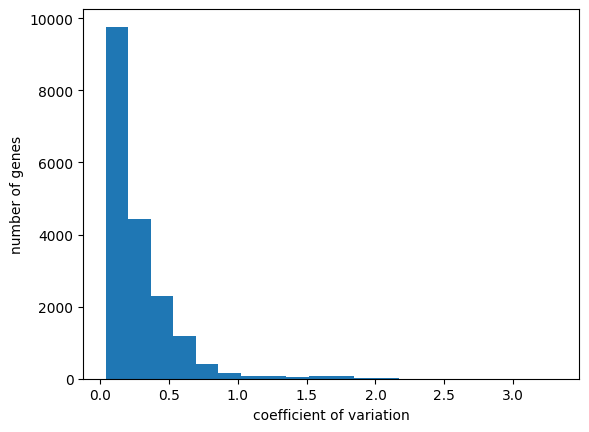

In [24]:
# call filter_cvs with thresh=CV_THRESH
expr_df = filter_cvs(expr_df, thresh=CV_THRESH)
expr_df.shape

In [25]:
# first save expr_df to file in gdrive for use in next notebook
expr_df.to_csv(DGEA_DIR + '/expr_df.csv', sep=',', index=None)

In [26]:
# then transpose expr_df to be samples x genes
expr_df = transpose_df(expr_df, 'Unnamed: 0', 'sample')
expr_df.head()

,sample,ENSMUSG00000000049,ENSMUSG00000000120,ENSMUSG00000000204,ENSMUSG00000000223,ENSMUSG00000000247,ENSMUSG00000000303,ENSMUSG00000000308,ENSMUSG00000000386,ENSMUSG00000000560,...,ENSMUSG00000118086,ENSMUSG00000118107,ENSMUSG00000118133,ENSMUSG00000118138,ENSMUSG00000118163,ENSMUSG00000118202,ENSMUSG00000118229,ENSMUSG00000118232,ENSMUSG00000118257,ENSMUSG00000118366
0,Mmus_C57-6J_GST_FLT_Rep1_M23,44.0,29.0,3.0,661.0,6.0,25.0,5.0,7.0,13.0,...,3.0,116.0,4.87,3.0,58.0,41.0,6.0,1.0,4.0,3.0
1,Mmus_C57-6J_GST_FLT_Rep2_M24,47.0,153.0,4.0,720.0,8.0,100.0,25.0,7.0,2.0,...,3.0,47.0,1.00,7.0,12.0,4.0,1.0,7.0,13.0,10.0
2,Mmus_C57-6J_GST_FLT_Rep3_M25,34.0,68.0,3.0,297.0,13.0,30.0,10.0,7.0,2.0,...,4.0,55.0,3.07,8.0,33.0,31.0,6.0,1.0,2.0,0.0
3,Mmus_C57-6J_GST_FLT_Rep4_M26,94.0,35.0,31.0,1564.0,3.0,78.0,8.0,18.0,4.0,...,10.0,203.0,6.47,8.0,78.0,46.0,12.0,9.0,10.0,3.0
4,Mmus_C57-6J_GST_FLT_Rep5_M27,14.0,32.0,13.0,1143.0,3.0,52.0,8.0,14.0,6.0,...,2.0,144.0,4.44,9.0,73.0,60.0,2.0,13.0,7.0,1.0


In [27]:
# determine the shape of the expr_df_T dataframe
expr_df.shape

(12, 2430)

In [28]:
# read in  metadata
url = 'https://osdr.nasa.gov/geode-py/ws/studies/OSD-' + OSD_DATASET + \
  '/download\?source=datamanager\&file=OSD-' + OSD_DATASET + '_metadata_OSD-' + GLDS_DATASET + '-ISA.zip'

!curl -L {url} -o {META_DIR}/metadata-{OSD_DATASET}.zip
!unzip -o {META_DIR}/metadata-{OSD_DATASET}.zip -d {META_DIR}

<>:3: SyntaxWarning: invalid escape sequence '\?'
<>:3: SyntaxWarning: invalid escape sequence '\?'
/tmp/ipykernel_33837/2785228226.py:3: SyntaxWarning: invalid escape sequence '\?'
  '/download\?source=datamanager\&file=OSD-' + OSD_DATASET + '_metadata_OSD-' + GLDS_DATASET + '-ISA.zip'


  % Total    % Received % Xferd  Average Speed   Time    Time     Time  Current
                                 Dload  Upload   Total   Spent    Left  Speed
100  3818  100  3818    0     0   5163      0 --:--:-- --:--:-- --:--:--  5166
100   99k  100   99k    0     0  98440      0  0:00:01  0:00:01 --:--:--  540k
Archive:  /content/DGEA/META/101/metadata-101.zip
 extracting: /content/DGEA/META/101/s_OSD-101.txt  
 extracting: /content/DGEA/META/101/a_OSD-101_rna-methylation-profiling_whole-transcriptome-bisulfite-sequencing_Illumina.txt  
 extracting: /content/DGEA/META/101/a_OSD-101_protein-expression-profiling_mass-spectrometry_Orbitrap Fusion(Thermo Scientific).txt  
 extracting: /content/DGEA/META/101/a_OSD-101_transcription-profiling_rna-sequencing-(rna-seq)_Illumina.txt  
 extracting: /content/DGEA/META/101/a_OSD-101_dna-methylation-profiling_whole-genome-bisulfite-sequencing_Illumina.txt  
 extracting: /content/DGEA/META/101/i_Investigation.txt  


In [29]:
# check metadata
meta_df = pd.read_csv(f"{META_DIR}/s_OSD-" + OSD_DATASET + ".txt", sep='\t')
meta_df.head()

,Source Name,Sample Name,Characteristics[Organism],Term Source REF,Term Accession Number,Characteristics[Strain],Term Source REF.1,Term Accession Number.1,Characteristics[Animal Source],Characteristics[Sex],...,Unit.2,Term Source REF.9,Term Accession Number.9,Parameter Value[Euthanasia Chemical],Term Source REF.10,Term Accession Number.10,Parameter Value[Carcass Storage Method],Comment[Source Description],Comment[LSDA Biospecimen ID],Comment[LSDA Biospecimen Subject ID]
0,RR1_GC_M33,Mmus_C57-6J_GST_GC_Rep1_M33,Mus musculus,NCBITAXON,http://purl.bioontology.org/ontology/NCBITAXON...,C57BL/6J,EFO,http://www.ebi.ac.uk/efo/EFO_0000606,Jackson Laboratory,Female,...,degree Celsius,UO,http://purl.obolibrary.org/obo/UO_0000027,Euthasol,RXNORM,http://purl.bioontology.org/ontology/RXNORM/11...,Mini Cold Bag to -80C freezer,intact carcass,5213,445
1,RR1_GC_M34,Mmus_C57-6J_GST_GC_Rep2_M34,Mus musculus,NCBITAXON,http://purl.bioontology.org/ontology/NCBITAXON...,C57BL/6J,EFO,http://www.ebi.ac.uk/efo/EFO_0000606,Jackson Laboratory,Female,...,degree Celsius,UO,http://purl.obolibrary.org/obo/UO_0000027,Euthasol,RXNORM,http://purl.bioontology.org/ontology/RXNORM/11...,Mini Cold Bag to -80C freezer,intact carcass,5213,445
2,RR1_GC_M35,Mmus_C57-6J_GST_GC_Rep3_M35,Mus musculus,NCBITAXON,http://purl.bioontology.org/ontology/NCBITAXON...,C57BL/6J,EFO,http://www.ebi.ac.uk/efo/EFO_0000606,Jackson Laboratory,Female,...,degree Celsius,UO,http://purl.obolibrary.org/obo/UO_0000027,Euthasol,RXNORM,http://purl.bioontology.org/ontology/RXNORM/11...,Mini Cold Bag to -80C freezer,intact carcass,5213,445
3,RR1_GC_M36,Mmus_C57-6J_GST_GC_Rep4_M36,Mus musculus,NCBITAXON,http://purl.bioontology.org/ontology/NCBITAXON...,C57BL/6J,EFO,http://www.ebi.ac.uk/efo/EFO_0000606,Jackson Laboratory,Female,...,degree Celsius,UO,http://purl.obolibrary.org/obo/UO_0000027,Euthasol,RXNORM,http://purl.bioontology.org/ontology/RXNORM/11...,Mini Cold Bag to -80C freezer,intact carcass,5213,445
4,RR1_GC_M37,Mmus_C57-6J_GST_GC_Rep5_M37,Mus musculus,NCBITAXON,http://purl.bioontology.org/ontology/NCBITAXON...,C57BL/6J,EFO,http://www.ebi.ac.uk/efo/EFO_0000606,Jackson Laboratory,Female,...,degree Celsius,UO,http://purl.obolibrary.org/obo/UO_0000027,Euthasol,RXNORM,http://purl.bioontology.org/ontology/RXNORM/11...,Mini Cold Bag to -80C freezer,intact carcass,5213,445


In [30]:
# change Factor Value[Spaceflight] to lower case
for i in range(len(meta_df)):
  meta_df.loc[i, 'Factor Value[Spaceflight]'] = meta_df.iloc[i]['Factor Value[Spaceflight]'].lower().strip()

In [31]:
# see how many samples are flight and how many are ground
meta_df['Factor Value[Spaceflight]'].value_counts()

,count
Factor Value[Spaceflight],
ground control,7
space flight,7
not applicable,2


In [32]:
# drop all values from expr_df and meta_df that are not either "Ground Control" or "Space Flight"
gc_samples = list(meta_df[meta_df['Factor Value[Spaceflight]'] == 'ground control']['Sample Name'])
sf_samples = list(meta_df[meta_df['Factor Value[Spaceflight]'] == 'space flight']['Sample Name'])
samples = gc_samples + sf_samples
expr_df = expr_df[expr_df['sample'].isin(samples)]
meta_df = meta_df[meta_df['Sample Name'].isin(samples)]

In [33]:
# check shape of final dataframes prior to analysis
print('expr shape: ', expr_df.shape)
print('meta shape: ', meta_df.shape)

expr shape:  (12, 2430)
meta shape:  (14, 48)


In [34]:
missing_samples = set(meta_df['Sample Name']) - set(expr_df['sample'])
print(missing_samples)

{'Pool of all FLT samples', 'Pool of all GC samples'}


In [35]:
# keep only metadata for samples in the RNA-seq expression data
meta_df = meta_df[meta_df['Sample Name'].isin(expr_df['sample'])]

print(set(expr_df['sample']) == set(meta_df['Sample Name']))

print('expr shape:', expr_df.shape)
print('meta shape:', meta_df.shape)
print(meta_df['Factor Value[Spaceflight]'].value_counts())

True
expr shape: (12, 2430)
meta shape: (12, 48)
Factor Value[Spaceflight]
ground control    6
space flight      6
Name: count, dtype: int64


### Data Preparation Findings

We started with 55,536 genes and applied the filtering steps from the class notebook, leaving 2,429 genes for analysis. We also noticed that the metadata contained two pooled sample records without matching RNA-seq measurements, so we excluded those records from our analysis.

Our final dataset contained 12 mice: six ground-control and six spaceflight samples.

# Run PCA

Here we run principal components analysis (PCA) to determine if the samples separate in the plane.

X shape:  (12, 2429)
y shape:  (12,)
explained variance ratio (first two components): [0.91291542 0.07578768]


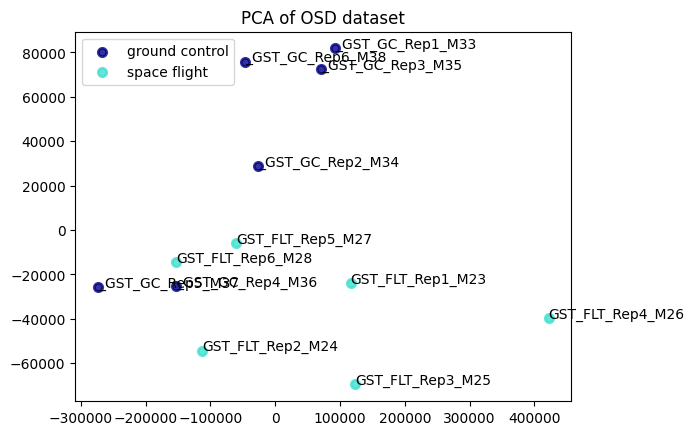

In [36]:
# call run_pca on expr_df_final
run_pca(expr_df, meta_df)

### PCA Findings

Our PCA plot showed some differences between the ground-control and spaceflight samples, although the groups did not separate completely. The first principal component explained approximately 91.29% of the variation, and the second explained approximately 7.58%.

This suggests that there may be differences in gene expression patterns between the groups, but the PCA alone cannot tell us which genes are responsible.

# Perform differential gene expression analysis

In [37]:
# First let's create a conditions table for 'Factor Value: Spaceflight'.
# We'll assign 0 for ground control and 1 for spaceflight
condition_dict=dict()
for sample in list(expr_df['sample']):
    val = meta_df[meta_df['Sample Name']==sample]['Factor Value[Spaceflight]'].values[0]
    if val.lower().strip() == 'ground control':
        condition_dict[sample] = 0
    elif val.lower().strip() == 'space flight':
        condition_dict[sample] = 1
    else:
      print('val ' + val + ' neither Ground Control nor Space Flight')
conditions =  pd.DataFrame.from_dict(condition_dict, orient='index')
conditions.columns = ['condition']


In [38]:
# examine conditions dataframe
for sample in expr_df['sample']:
    factor = meta_df.loc[
        meta_df['Sample Name'] == sample,
        'Factor Value[Spaceflight]'
    ].values[0]

    print(sample, factor, conditions.loc[sample, 'condition'])

Mmus_C57-6J_GST_FLT_Rep1_M23 space flight 1
Mmus_C57-6J_GST_FLT_Rep2_M24 space flight 1
Mmus_C57-6J_GST_FLT_Rep3_M25 space flight 1
Mmus_C57-6J_GST_FLT_Rep4_M26 space flight 1
Mmus_C57-6J_GST_FLT_Rep5_M27 space flight 1
Mmus_C57-6J_GST_FLT_Rep6_M28 space flight 1
Mmus_C57-6J_GST_GC_Rep1_M33 ground control 0
Mmus_C57-6J_GST_GC_Rep2_M34 ground control 0
Mmus_C57-6J_GST_GC_Rep3_M35 ground control 0
Mmus_C57-6J_GST_GC_Rep4_M36 ground control 0
Mmus_C57-6J_GST_GC_Rep5_M37 ground control 0
Mmus_C57-6J_GST_GC_Rep6_M38 ground control 0


In [39]:
# make sure there are exactly 2 conditions for DGEA
set(meta_df['Factor Value[Spaceflight]'])


{'ground control', 'space flight'}

In [40]:
# create dataframe with 'sample' column removed for DESeq2
import numpy as np
counts = expr_df.set_index('sample')
# check for non-numeric
counts.applymap(np.isreal)
# convert all cells to integers
counts = counts.astype(int)
counts.shape

(12, 2429)

You can read more about the pyDeseq2 package in [this document](https://pydeseq2.readthedocs.io/en/stable/api/index.html#).

In [41]:
# run DESeq2 comparing space flight (1) against ground control (0)
# store the results in a dataframe called "res"
dds = DeseqDataSet(counts=counts, metadata=conditions, design_factors="condition")
dds.deseq2()
stats_results = DeseqStats(dds, contrast = ('condition', 1, 0))
stats_results.summary()
res = stats_results.results_df

Using None as control genes, passed at DeseqDataSet initialization


/tmp/ipykernel_33837/3004068608.py:3: DeprecationWarning: design_factors is deprecated and will soon be removed.Please consider providing a formulaic formula using the design argumentinstead.
  dds = DeseqDataSet(counts=counts, metadata=conditions, design_factors="condition")
Fitting size factors...
... done in 0.00 seconds.

Fitting dispersions...
... done in 6.00 seconds.

Fitting dispersion trend curve...
/usr/local/lib/python3.13/dist-packages/pydeseq2/dds.py:822: UserWarning: The dispersion trend curve fitting did not converge. Switching to a mean-based dispersion trend.
  self._fit_parametric_dispersion_trend(vst)
... done in 0.13 seconds.

Fitting MAP dispersions...
... done in 4.03 seconds.

Fitting LFCs...
... done in 2.28 seconds.

Calculating cook's distance...
... done in 0.01 seconds.

Replacing 0 outlier genes.

Running Wald tests...


Log2 fold change & Wald test p-value: condition 1 vs 0
                      baseMean  log2FoldChange     lfcSE      stat    pvalue  \
ENSMUSG00000000049   45.241315       -0.663903  0.780977 -0.850092  0.395274   
ENSMUSG00000000120   56.306129       -0.055578  0.509808 -0.109018  0.913188   
ENSMUSG00000000204    6.470372        0.692021  0.646167  1.070963  0.284186   
ENSMUSG00000000223  844.094995       -0.316750  0.472678 -0.670118  0.502782   
ENSMUSG00000000247    5.206466        0.604567  0.637882  0.947773  0.343245   
...                        ...             ...       ...       ...       ...   
ENSMUSG00000118202   21.269504        1.694347  0.601980  2.814622  0.004883   
ENSMUSG00000118229   12.883992       -2.116175  0.814559 -2.597940  0.009378   
ENSMUSG00000118232    5.937322       -0.297268  0.650322 -0.457109  0.647593   
ENSMUSG00000118257    5.783278        0.204771  0.581850  0.351931  0.724890   
ENSMUSG00000118366    4.116406       -1.218382  0.908442 -1.34117

... done in 0.75 seconds.



In [42]:
# extract results of the DESeq2 experiment where  padj < 0.05, and log2fc > LOG2FC_THRESH
sigs = res[(res.padj < ALPHA_LEVEL) & (abs(res.log2FoldChange) > LOG2FC_THRESH)]
print(sigs.shape)
sigs.head()
sigs.to_csv(DGEA_DIR + '/sigs.csv', sep=',')

(0, 6)


In [43]:
# write differentially expressed gene list to file
deg_genes = list(sigs.index)
with open(f"{DGEA_DIR}/deg_genes-" + OSD_DATASET + ".txt", "w") as f:
  for gene in deg_genes:
    f.write(gene + "\n")
f.close()

# check gene file
!head {DGEA_DIR}/deg_genes-{OSD_DATASET}.txt

In [44]:
# write list of background genes to file
bg_genes = list(expr_df.drop(columns=['sample']))
with open(f"{DGEA_DIR}/background_genes-" + OSD_DATASET + ".txt", "w") as f:
  for gene in bg_genes:
    f.write(gene + "\n")
f.close()

# check gene file
!head {DGEA_DIR}/background_genes-{OSD_DATASET}.txt

ENSMUSG00000000049
ENSMUSG00000000120
ENSMUSG00000000204
ENSMUSG00000000223
ENSMUSG00000000247
ENSMUSG00000000303
ENSMUSG00000000308
ENSMUSG00000000386
ENSMUSG00000000560
ENSMUSG00000000627


# Create volcano plot

You can learn more about how this volcano plot was generated reading [this article](https://bioinformatics.ccr.cancer.gov/docs/pies-2023/pies_lesson4/).

INFO:biothings.client:Finished.


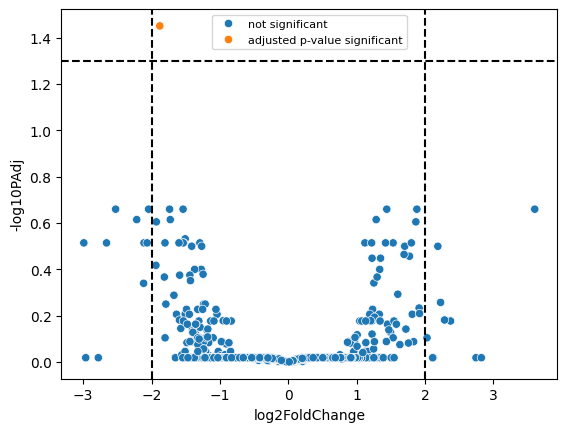

In [45]:
# import Python modules for plotting volcano
import pandas
import numpy
import matplotlib.pyplot as plt
import seaborn
# calculate significance cutoff using alpha level
pvalue_cutoff = -numpy.log10(ALPHA_LEVEL)

# create column for -log10PAdj from existing padj
res['-log10PAdj'] = -numpy.log10(res['padj'])

# create column for significance from existing log2FoldChange and -log10PAdj
significance = []
for i in range(len(res)):
    if res.iloc[i]['log2FoldChange'] > LOG2FC_THRESH and res.iloc[i]['-log10PAdj'] > pvalue_cutoff:
        significance.append('significantly up-regulated')
    elif res.iloc[i]['log2FoldChange'] < -LOG2FC_THRESH and res.iloc[i]['-log10PAdj'] > pvalue_cutoff:
        significance.append('significantly down-regulated')
    elif res.iloc[i]['padj'] < ALPHA_LEVEL:
        significance.append('adjusted p-value significant')
    else:
        significance.append('not significant')

res['significance'] = significance
# plot the degs
plot1 = seaborn.scatterplot(res, x = "log2FoldChange", y = "-log10PAdj", hue = "significance")

# sort to get top 10 significant genes
top10 = sigs[sigs['padj'] < ALPHA_LEVEL].sort_values(by=['padj', 'log2FoldChange'], ascending=[True, False]).head(10)

# add gene_symbol to top10
gene_symbol_list = get_symbol_from_id(list(top10.index))
top10['gene_symbol'] = gene_symbol_list

# add -log10PAdj to top10
top10['-log10PAdj'] = -numpy.log10(top10['padj'])

# annotate top 10 significant genes
for i in range(top10.shape[0]):
    gene = top10.iloc[i]
    plt.text(gene['log2FoldChange'], gene['-log10PAdj'], gene['gene_symbol'], fontsize=7, ha='right')

# draw a line at the significance threshold
plt.axhline(y = pvalue_cutoff, color='black', linestyle='--')

# draw 2 lines at fold change threshold
plt.axvline(x = LOG2FC_THRESH, color = 'black', linestyle='--')
plt.axvline(x = -LOG2FC_THRESH, color='black', linestyle='--')

# set font size for legend
plt.legend(fontsize=8)


In [46]:
sigs

,baseMean,log2FoldChange,lfcSE,stat,pvalue,padj


### Differential Gene Expression Findings

We used DESeq2 to compare gene expression between the spaceflight and ground-control mice. Of the 2,429 genes analyzed, none met both of our selected thresholds: an adjusted p-value below 0.05 and an absolute log2 fold change greater than 2.

Our volcano plot showed one gene that passed the adjusted p-value threshold, but its fold change was below our cutoff. Therefore, our analysis did not identify any genes meeting both criteria.

This does not necessarily mean spaceflight has no effect on muscle gene expression. Our results may also be influenced by the sample size, filtering methods, and statistical thresholds.

# Check your work before moving on

In [47]:
# time the notebook
import datetime
end_time = datetime.datetime.now()
print('notebook end time: ', end_time.strftime('%Y-%m-%d %H:%M:%S'))

print('notebook runtime: ', end_time - start_time)
#

notebook end time:  2026-11-23 20:34:07
notebook runtime:  0:01:41.818557
